In [1]:
# ==========================================================
# NOTEBOOK 2
# AI-ASSISTED CROP TYPE MAPPING
# RANDOM FOREST CLASSIFICATION
#
# Study Area : Karnal District
# Season     : Kharif
# ==========================================================

# ==========================================================
# IMPORT LIBRARIES
# ==========================================================

import warnings
warnings.filterwarnings("ignore")

import gc
import os
from pathlib import Path

import numpy as np
import pandas as pd

import geopandas as gpd

import rasterio
from rasterio.plot import show
from rasterio.mask import mask

import matplotlib.pyplot as plt
import matplotlib as mpl

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    cohen_kappa_score
)

# ==========================================================
# PUBLICATION SETTINGS
# ==========================================================

plt.style.use("default")

mpl.rcParams["figure.dpi"] = 140
mpl.rcParams["savefig.dpi"] = 600

mpl.rcParams["font.family"] = "DejaVu Sans"

mpl.rcParams["axes.titleweight"] = "bold"
mpl.rcParams["axes.labelweight"] = "bold"

mpl.rcParams["axes.titlesize"] = 18
mpl.rcParams["axes.labelsize"] = 12

# ==========================================================
# PROJECT INFORMATION
# ==========================================================

DISTRICT = "Karnal"

SEASON = "Kharif"

print("="*70)
print("PROJECT 7")
print("AI-Assisted Crop Type Mapping using Multi-season Sentinel-2")
print("="*70)
print(f"District : {DISTRICT}")
print(f"Season   : {SEASON}")
print("="*70)

# ==========================================================
# PROJECT PATHS
# ==========================================================

PROJECT_DIR = Path(
"/home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main"
)

DATA_DIR = PROJECT_DIR / "data"

BOUNDARY_DIR = DATA_DIR / "boundary"

PREPROCESS_RASTER_DIR = PROJECT_DIR / "outputs" / "rasters"

OUTPUT_DIR = PROJECT_DIR / "outputs"

ML_DIR = OUTPUT_DIR / "machine_learning"

ML_FIGURE_DIR = ML_DIR / "figures"

ML_TABLE_DIR = ML_DIR / "tables"

ML_MODEL_DIR = ML_DIR / "models"

ML_RASTER_DIR = ML_DIR / "rasters"

# ==========================================================
# CREATE OUTPUT FOLDERS
# ==========================================================

for folder in [

    ML_DIR,

    ML_FIGURE_DIR,

    ML_TABLE_DIR,

    ML_MODEL_DIR,

    ML_RASTER_DIR

]:

    folder.mkdir(

        parents=True,

        exist_ok=True

    )

print("\nOutput folders verified.")

# ==========================================================
# FILE PATHS
# ==========================================================

BOUNDARY_FILE = BOUNDARY_DIR / "Karnal_Boundary.shp"

FEATURE_STACK = PREPROCESS_RASTER_DIR / "Karnal_Kharif_FeatureStack.tif"

NDVI_FILE = PREPROCESS_RASTER_DIR / "Karnal_Kharif_NDVI.tif"

NDWI_FILE = PREPROCESS_RASTER_DIR / "Karnal_Kharif_NDWI.tif"

SAVI_FILE = PREPROCESS_RASTER_DIR / "Karnal_Kharif_SAVI.tif"

NDBI_FILE = PREPROCESS_RASTER_DIR / "Karnal_Kharif_NDBI.tif"

print("\nInput files configured successfully.")

print("="*70)
print("Notebook 2 Initialization Complete")
print("="*70)

PROJECT 7
AI-Assisted Crop Type Mapping using Multi-season Sentinel-2
District : Karnal
Season   : Kharif

Output folders verified.

Input files configured successfully.
Notebook 2 Initialization Complete


LOADING DISTRICT BOUNDARY


,Shape_Leng,STATUS,ADM1_CODE,ADM0_NAME,STR2_YEAR,ADM2_NAME,ADM0_CODE,EXP2_YEAR,Shape_Area,ADM2_CODE,DISP_AREA,ADM1_NAME,geometry
0,2.773671,Member State,1492,India,1990,Karnal,115,3000,0.240933,17660,NO,Haryana,"POLYGON ((76.48194 29.51891, 76.49 29.53094, 7..."



CRS
EPSG:4326

Total Bounds
[76.4819394  29.44565149 77.21112733 29.99548987]

Total Area
0.240933


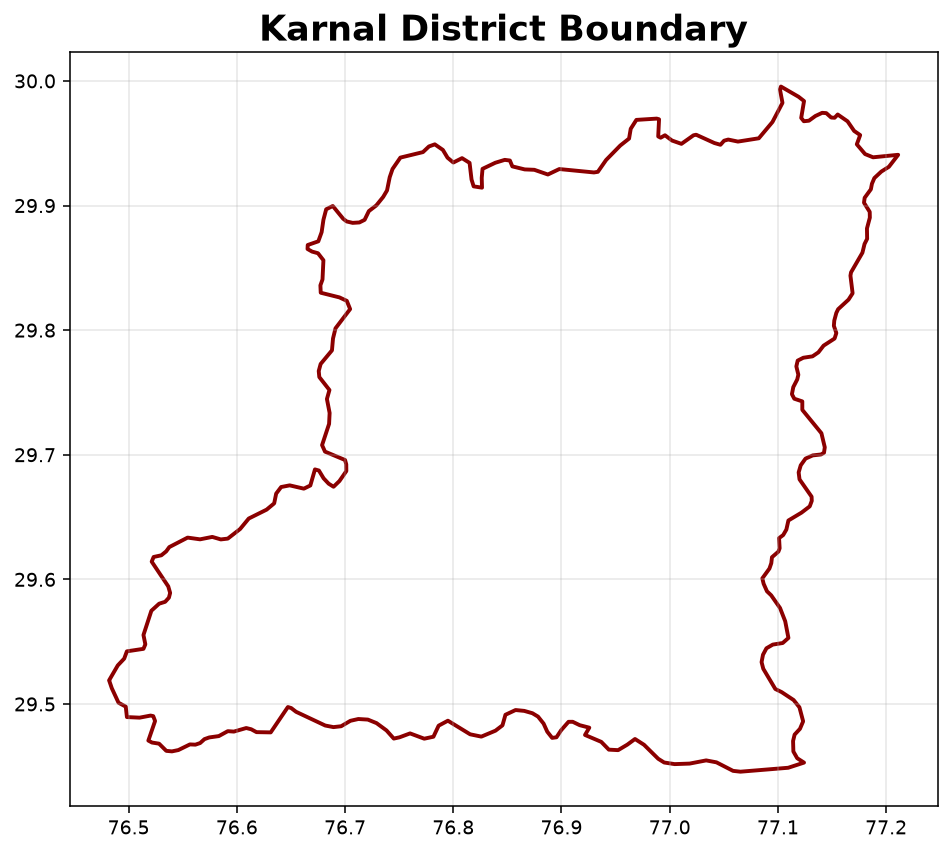

In [2]:
# ==========================================================
# CELL 2 : LOAD DISTRICT BOUNDARY
# ==========================================================

print("="*70)
print("LOADING DISTRICT BOUNDARY")
print("="*70)

aoi = gpd.read_file(BOUNDARY_FILE)

display(aoi)

print()

print("CRS")
print(aoi.crs)

print()

print("Total Bounds")

print(aoi.total_bounds)

print()

print("Total Area")

print(round(aoi.geometry.area.iloc[0],6))

# ==========================================================
# PUBLICATION MAP
# ==========================================================

fig, ax = plt.subplots(figsize=(8,8))

aoi.plot(

    ax=ax,

    facecolor="none",

    edgecolor="darkred",

    linewidth=2

)

ax.set_title(

    f"{DISTRICT} District Boundary",

    fontsize=18,

    fontweight="bold"

)

ax.grid(alpha=0.3)

plt.show()

plt.close()

In [3]:
# ==========================================================
# CELL 3 : LOAD SENTINEL-2 BANDS
# ==========================================================

SELECTED_BANDS = PREPROCESS_RASTER_DIR / "Karnal_Kharif_SelectedBands.tif"

print("="*70)
print("LOADING SENTINEL-2 BANDS")
print("="*70)

src = rasterio.open(SELECTED_BANDS)

bands = src.read()

print()

print("Shape")

print(bands.shape)

print()

print("CRS")

print(src.crs)

print()

print("Resolution")

print(src.res)

print()

print("Bounds")

print(src.bounds)

print()

print("Band Count")

print(src.count)

print()

print("Band Names")

print("""

Band 1 -> Blue (B2)

Band 2 -> Green (B3)

Band 3 -> Red (B4)

Band 4 -> NIR (B8)

Band 5 -> SWIR1 (B11)

Band 6 -> SWIR2 (B12)

""")

LOADING SENTINEL-2 BANDS

Shape
(6, 6122, 8118)

CRS
EPSG:4326

Resolution
(8.983152841195215e-05, 8.983152841195215e-05)

Bounds
BoundingBox(left=76.48193446923717, bottom=29.44560720356856, right=77.2111868168854, top=29.99555582050653)

Band Count
6

Band Names


Band 1 -> Blue (B2)

Band 2 -> Green (B3)

Band 3 -> Red (B4)

Band 4 -> NIR (B8)

Band 5 -> SWIR1 (B11)

Band 6 -> SWIR2 (B12)




In [4]:
# ==========================================================
# CELL 4 : LOAD ALL RASTERS
# Verify CRS, Resolution, Transform & Dimensions
# ==========================================================

print("="*70)
print("LOADING DERIVED RASTERS")
print("="*70)

# ----------------------------------------------------------
# NDVI
# ----------------------------------------------------------
ndvi_src = rasterio.open(NDVI_FILE)
ndvi = ndvi_src.read(1)

# ----------------------------------------------------------
# NDWI
# ----------------------------------------------------------
ndwi_src = rasterio.open(NDWI_FILE)
ndwi = ndwi_src.read(1)

# ----------------------------------------------------------
# SAVI
# ----------------------------------------------------------
savi_src = rasterio.open(SAVI_FILE)
savi = savi_src.read(1)

# ----------------------------------------------------------
# NDBI
# ----------------------------------------------------------
ndbi_src = rasterio.open(NDBI_FILE)
ndbi = ndbi_src.read(1)

print("✓ NDVI Loaded")
print("✓ NDWI Loaded")
print("✓ SAVI Loaded")
print("✓ NDBI Loaded")

print("\n")

# ==========================================================
# VERIFY DIMENSIONS
# ==========================================================

datasets = {
    "SelectedBands": src,
    "NDVI": ndvi_src,
    "NDWI": ndwi_src,
    "SAVI": savi_src,
    "NDBI": ndbi_src
}

verification = []

for name, ds in datasets.items():

    verification.append({

        "Dataset": name,
        "Width": ds.width,
        "Height": ds.height,
        "Bands": ds.count,
        "CRS": str(ds.crs),
        "Resolution": ds.res,
        "Transform": str(ds.transform)[:60]

    })

verify_df = pd.DataFrame(verification)

display(verify_df)

# ==========================================================
# SAVE TABLE
# ==========================================================

verify_df.to_csv(
    ML_TABLE_DIR / f"{DISTRICT}_{SEASON}_Raster_Verification.csv",
    index=False
)

print("\n✓ Raster verification table saved.")

LOADING DERIVED RASTERS
✓ NDVI Loaded
✓ NDWI Loaded
✓ SAVI Loaded
✓ NDBI Loaded




,Dataset,Width,Height,Bands,CRS,Resolution,Transform
0,SelectedBands,8118,6122,6,EPSG:4326,"(8.983152841195215e-05, 8.983152841195215e-05)","| 0.00, 0.00, 76.48|\n| 0.00,-0.00, 30.00|\n| ..."
1,NDVI,8118,6122,1,EPSG:4326,"(8.983152841195215e-05, 8.983152841195215e-05)","| 0.00, 0.00, 76.48|\n| 0.00,-0.00, 30.00|\n| ..."
2,NDWI,8118,6122,1,EPSG:4326,"(8.983152841195215e-05, 8.983152841195215e-05)","| 0.00, 0.00, 76.48|\n| 0.00,-0.00, 30.00|\n| ..."
3,SAVI,8118,6122,1,EPSG:4326,"(8.983152841195215e-05, 8.983152841195215e-05)","| 0.00, 0.00, 76.48|\n| 0.00,-0.00, 30.00|\n| ..."
4,NDBI,8118,6122,1,EPSG:4326,"(8.983152841195215e-05, 8.983152841195215e-05)","| 0.00, 0.00, 76.48|\n| 0.00,-0.00, 30.00|\n| ..."



✓ Raster verification table saved.


In [5]:
# ==========================================================
# HELPER FUNCTION : SAVE FIGURE
# ==========================================================

from pathlib import Path

def save_figure(
    filename,
    dpi=600,
    transparent=False
):
    """
    Save current matplotlib figure.
    """

    filepath = ML_FIGURE_DIR / f"{filename}.png"

    plt.savefig(
        filepath,
        dpi=dpi,
        bbox_inches="tight",
        transparent=transparent
    )

    print(f"✓ Figure saved -> {filepath}")

✓ Figure saved -> /home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/machine_learning/figures/Karnal_Kharif_Multi_Index_Comparison.png


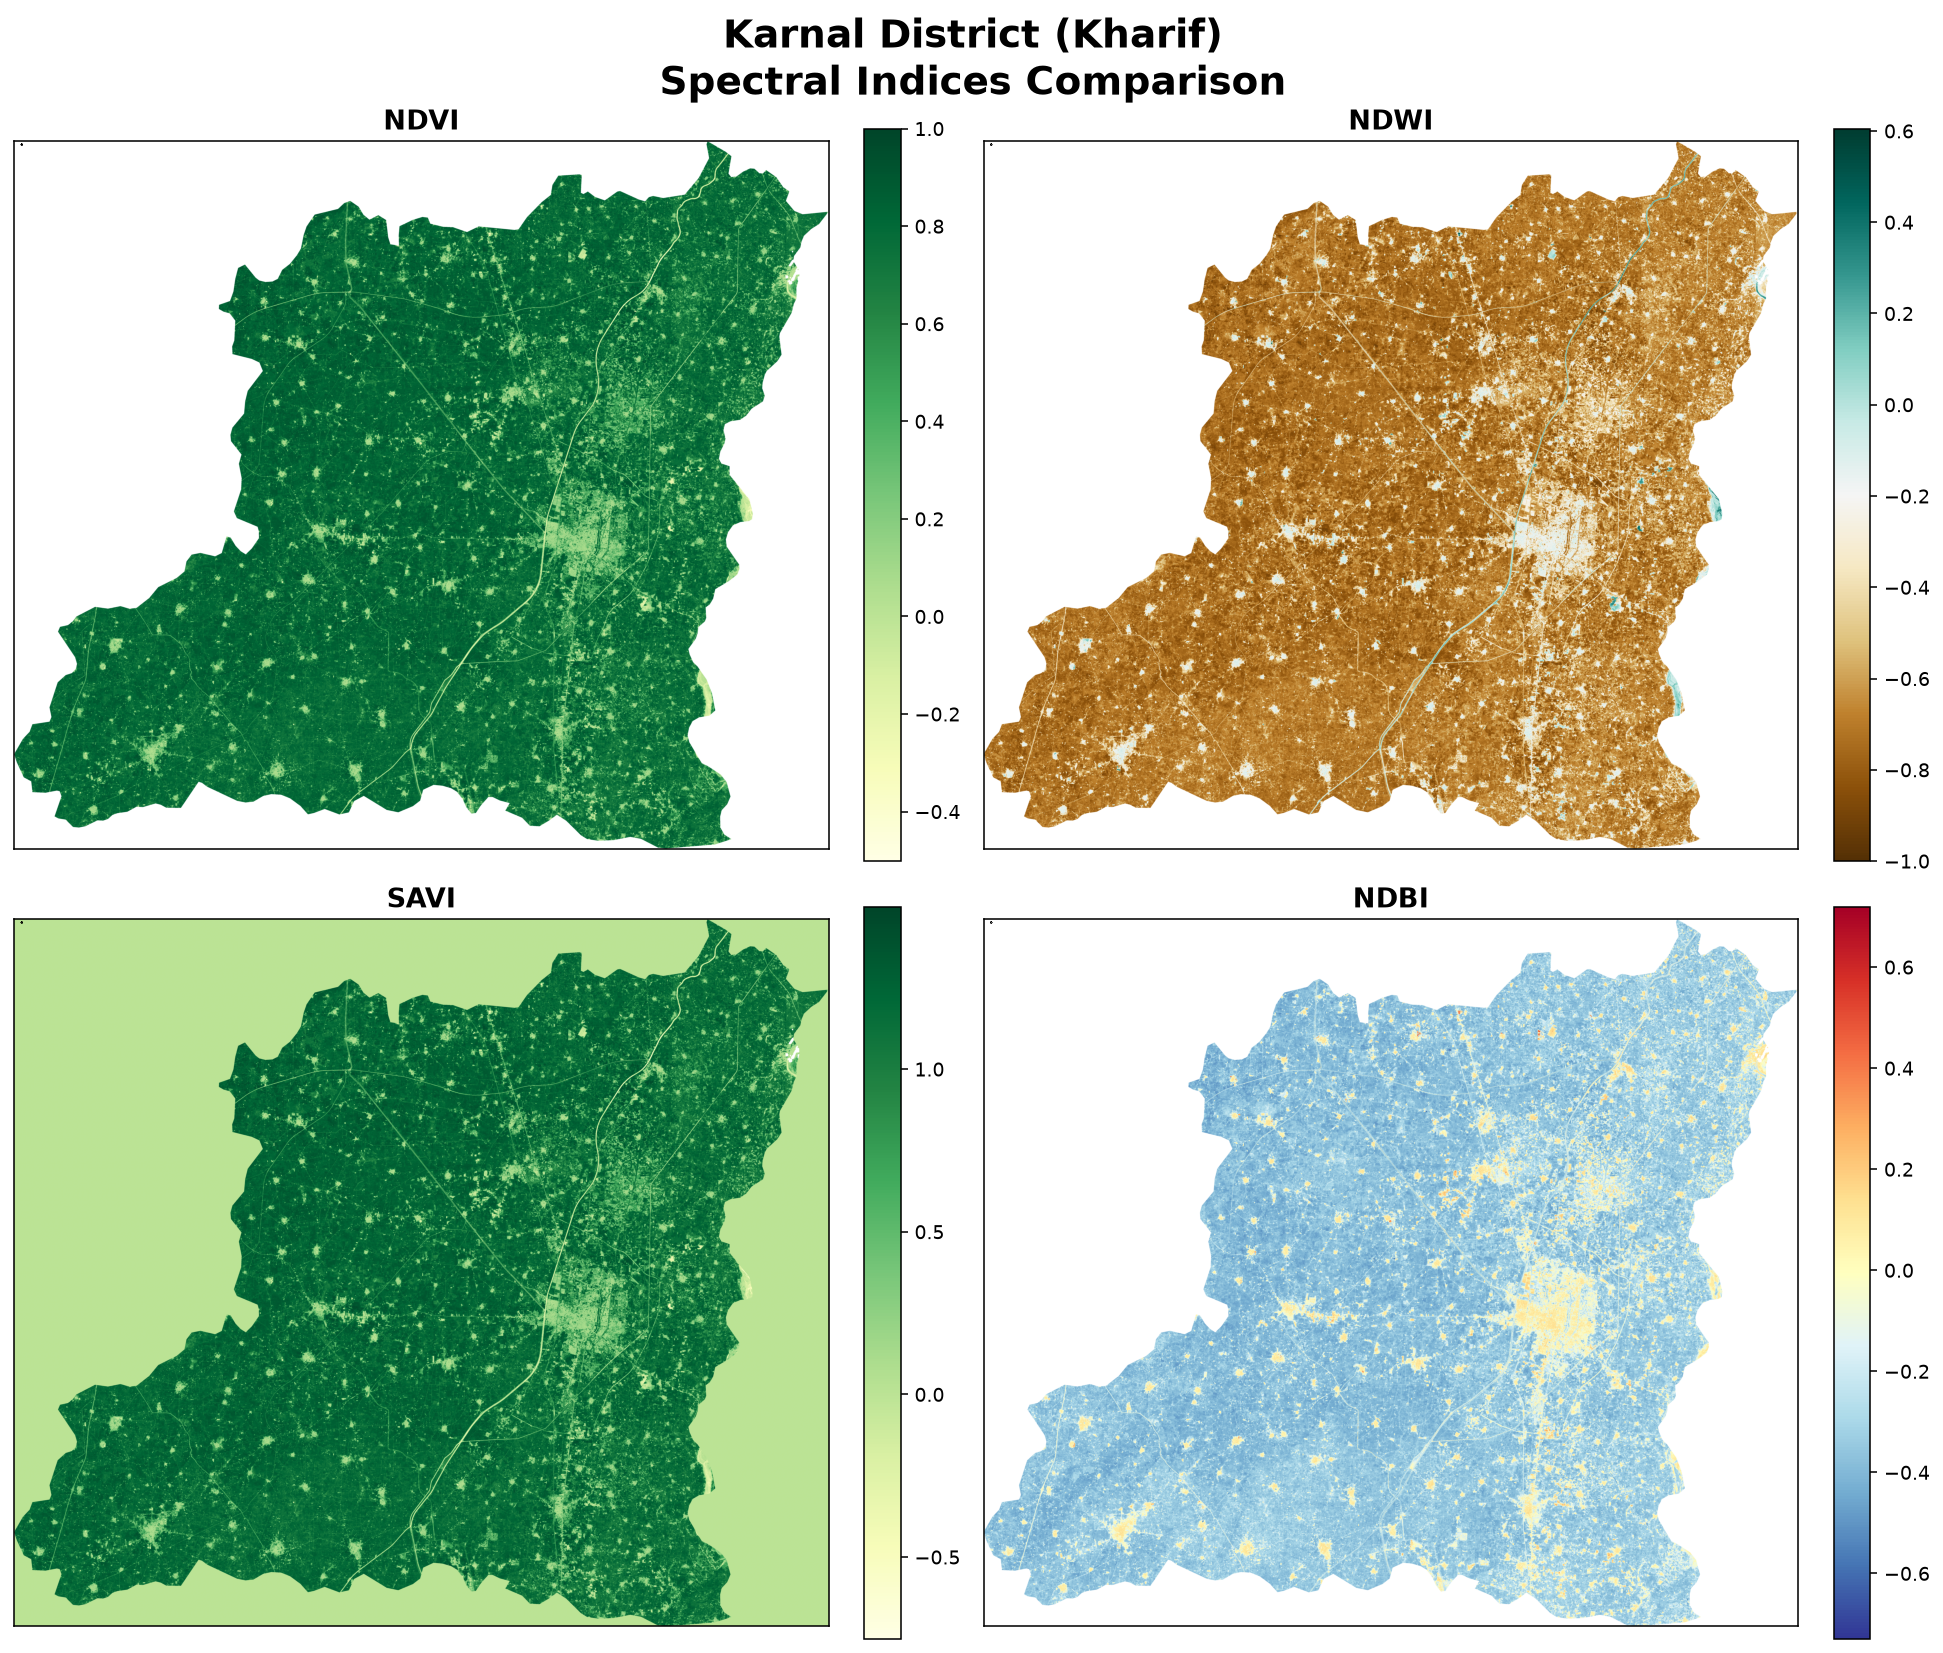

In [6]:
# ==========================================================
# CELL 5 : PUBLICATION QUALITY MULTI-INDEX COMPARISON
# ==========================================================

from matplotlib.colors import LinearSegmentedColormap

# ----------------------------------------------------------
# Create Figure
# ----------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14,12)
)

fig.suptitle(
    f"{DISTRICT} District ({SEASON})\nSpectral Indices Comparison",
    fontsize=20,
    fontweight="bold"
)

# ----------------------------------------------------------
# Colormaps
# ----------------------------------------------------------

ndvi_cmap = "YlGn"

ndwi_cmap = "BrBG"

savi_cmap = "YlGn"

ndbi_cmap = "RdYlBu_r"

plots = [

    (ndvi, "NDVI", ndvi_cmap),

    (ndwi, "NDWI", ndwi_cmap),

    (savi, "SAVI", savi_cmap),

    (ndbi, "NDBI", ndbi_cmap)

]

for ax, (img, title, cmap) in zip(axes.flat, plots):

    im = ax.imshow(
        img,
        cmap=cmap,
        vmin=np.nanmin(img),
        vmax=np.nanmax(img)
    )

    aoi.boundary.plot(
        ax=ax,
        edgecolor="black",
        linewidth=1
    )

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xticks([])
    ax.set_yticks([])

    plt.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

plt.tight_layout()

# ==========================================================
# SAVE FIGURE
# ==========================================================

save_figure(
    f"{DISTRICT}_{SEASON}_Multi_Index_Comparison"
)

plt.show()

plt.close()

In [7]:
pip install pandas scikit-learn matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# -------------------------
# Load Dataset
# -------------------------
df = pd.read_csv("/home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/Karnal_Kharif_Training_Data.csv")

# -------------------------
# Remove unwanted columns
# -------------------------
df = df.drop(columns=["system:index", ".geo"])

# -------------------------
# Features & Labels
# -------------------------
X = df.drop("class", axis=1)
y = df["class"]

# -------------------------
# Train-Test Split
# -------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# -------------------------
# Random Forest
# -------------------------
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# -------------------------
# Prediction
# -------------------------
pred = model.predict(X_test)

# -------------------------
# Accuracy
# -------------------------
print("\nAccuracy")
print(accuracy_score(y_test, pred))

print("\nClassification Report")
print(classification_report(y_test, pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, pred))

# -------------------------
# Feature Importance
# -------------------------
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print("\nFeature Importance")
print(importance)

# -------------------------
# Save Model
# -------------------------
joblib.dump(model, "Karnal_RF_Model.pkl")

print("\nModel Saved Successfully")


Accuracy
0.7835616438356164

Classification Report
              precision    recall  f1-score   support

           0       0.78      0.86      0.82       300
           1       0.80      0.66      0.73       130
           2       0.59      0.53      0.56       150
           3       0.95      0.99      0.97       150

    accuracy                           0.78       730
   macro avg       0.78      0.76      0.77       730
weighted avg       0.78      0.78      0.78       730


Confusion Matrix
[[258  10  28   4]
 [ 17  86  27   0]
 [ 56  11  79   4]
 [  1   0   0 149]]

Feature Importance
  Feature  Importance
2      B2    0.142711
8    NDWI    0.132786
0     B11    0.107045
1     B12    0.104816
7    NDVI    0.095453
5      B8    0.089003
9    SAVI    0.088590
4      B4    0.082627
3      B3    0.081770
6    NDBI    0.075199

Model Saved Successfully


In [2]:
import rasterio
import numpy as np
import os

# =====================================================
# Folder containing all exported rasters
# =====================================================
raster_dir = "/home/minato/project/main project/Crop-Type-Mapping-using-Multi-Season-Satellite-Data-ML-main/outputs/rasters"

# =====================================================
# File paths
# =====================================================
bands_file = os.path.join(raster_dir, "Karnal_Kharif_SelectedBands.tif")
ndvi_file  = os.path.join(raster_dir, "Karnal_Kharif_NDVI.tif")
ndwi_file  = os.path.join(raster_dir, "Karnal_Kharif_NDWI.tif")
ndbi_file  = os.path.join(raster_dir, "Karnal_Kharif_NDBI.tif")
savi_file  = os.path.join(raster_dir, "Karnal_Kharif_SAVI.tif")

# =====================================================
# Read Sentinel-2 bands
# =====================================================
with rasterio.open(bands_file) as src:
    bands = src.read()          # (6, rows, cols)
    profile = src.profile
    rows = src.height
    cols = src.width

print("Sentinel Bands Shape :", bands.shape)

# =====================================================
# Read Spectral Indices
# =====================================================
with rasterio.open(ndvi_file) as src:
    ndvi = src.read(1)

with rasterio.open(ndwi_file) as src:
    ndwi = src.read(1)

with rasterio.open(ndbi_file) as src:
    ndbi = src.read(1)

with rasterio.open(savi_file) as src:
    savi = src.read(1)

print("NDVI Shape :", ndvi.shape)
print("NDWI Shape :", ndwi.shape)
print("NDBI Shape :", ndbi.shape)
print("SAVI Shape :", savi.shape)

# =====================================================
# Create 10-band Feature Stack
# Order MUST match training CSV
# B2 B3 B4 B8 B11 B12 NDVI NDWI NDBI SAVI
# =====================================================
feature_stack = np.concatenate([
    bands,
    ndvi[np.newaxis, :, :],
    ndwi[np.newaxis, :, :],
    ndbi[np.newaxis, :, :],
    savi[np.newaxis, :, :]
], axis=0)

print("\nFeature Stack Shape :", feature_stack.shape)
print("Rows :", rows)
print("Cols :", cols)

# =====================================================
# Check
# =====================================================
assert feature_stack.shape[0] == 10, "Error: Feature stack must contain exactly 10 bands."

print("\n✅ Feature stack created successfully.")

Sentinel Bands Shape : (6, 6122, 8118)


/tmp/ipykernel_8014/593244671.py:34: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  ndvi = src.read(1)
/tmp/ipykernel_8014/593244671.py:37: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  ndwi = src.read(1)
/tmp/ipykernel_8014/593244671.py:40: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  ndbi = src.read(1)
/tmp/ipykernel_8014/593244671.py:43: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  savi = src.read(1)


NDVI Shape : (6122, 8118)
NDWI Shape : (6122, 8118)
NDBI Shape : (6122, 8118)
SAVI Shape : (6122, 8118)

Feature Stack Shape : (10, 6122, 8118)
Rows : 6122
Cols : 8118

✅ Feature stack created successfully.


In [ ]:
import numpy as np
import joblib

# =====================================================
# Load trained Random Forest model
# =====================================================
model_path = "Karnal_RF_Model.pkl"

rf = joblib.load(model_path)

print("✅ Random Forest model loaded.")

# =====================================================
# Convert feature stack into ML format
# (bands, rows, cols) -> (pixels, bands)
# =====================================================
X = feature_stack.reshape(10, -1).T

print("Feature Matrix:", X.shape)

# =====================================================
# Remove NaN / Inf values
# =====================================================
X = np.nan_to_num(
    X,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

print("Starting prediction...")

prediction = rf.predict(X)

print("Prediction completed.")

classified = prediction.reshape(rows, cols)

print("Classification Shape:", classified.shape)

✅ Random Forest model loaded.
Feature Matrix: (49698396, 10)
Starting prediction...


/home/minato/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
